# 03 · Cinética de flotación batch

> ⚠️ **DATOS SINTÉTICOS.** El dataset de planta no tiene pruebas batch de laboratorio. Los datos de este
> notebook se **generan** con un modelo conocido más ruido, para mostrar el procedimiento de ajuste y
> verificar que recupera los parámetros verdaderos. **No son mediciones reales** y no dicen nada sobre
> esta planta.

En flotación inversa lo que flota es la **sílice** (ganga) con la amina. La prueba batch mide la
recuperación acumulada de SiO₂ al espumado en el tiempo. Dos modelos de dos parámetros:

- **Primer orden**: R(t) = R∞ (1 − e^(−kt)). Una sola constante cinética.
- **Klimpel**: R(t) = R∞ [1 − (1 − e^(−kt)) / (kt)]. Distribución rectangular de constantes entre 0 y k
  (partículas que flotan rápido y lento).

R∞ = recuperación máxima (%), acotada físicamente a [0, 100]; k = constante cinética (min⁻¹), k > 0.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import SEED
from src.kinetics import MODELS, fit_kinetic, klimpel, synthetic_batch_test
from src.viz import AQUA, BLUE, GRAY, ORANGE, TEXT, save, set_style

set_style()
pd.set_option("display.width", 160)

## 1. Generación de la prueba batch (SINTÉTICA)

Tiempos típicos de una prueba de laboratorio (8 puntos, de 15 s a 8 min). Modelo generador: **Klimpel**
con R∞ = 90 % y k = 1,5 min⁻¹, más ruido normal de 1,5 puntos (error típico de ensayo y muestreo).

In [2]:
TIMES = np.array([0.25, 0.5, 1, 2, 3, 4, 6, 8])  # min
TRUE = {"r_inf": 90.0, "k": 1.5}
NOISE_SD = 1.5

recovery = synthetic_batch_test(TIMES, **TRUE, noise_sd=NOISE_SD, model=klimpel, seed=SEED)
batch = pd.DataFrame({"t_min": TIMES, "R_SiO2_pct_SINTETICO": recovery.round(2)})
batch

,t_min,R_SiO2_pct_SINTETICO
0,0.25,15.41
1,0.50,25.12
2,1.00,44.51
3,2.00,62.90
4,3.00,67.30
5,4.00,73.08
6,6.00,80.19
7,8.00,82.03


## 2. Ajuste con `curve_fit` e IC al 95 %

- `bounds`: 0 ≤ R∞ ≤ 100 y k > 0. Sin ellos, el optimizador puede devolver R∞ > 100 %, que no es físico.
- **IC con t de Student**: θ̂ ± t(0,975; n − p) · EE. Con n = 8 y p = 2 hay 6 grados de libertad;
  t = 2,45 en vez de 1,96 de la normal, así que el IC es un 25 % más ancho, como corresponde con pocos puntos.
- El EE sale de la covarianza de `curve_fit`, con σ estimado desde los residuos (`absolute_sigma=False`).

In [3]:
fits = {name: fit_kinetic(model, TIMES, recovery) for name, model in MODELS.items()}

rows = []
for name, f in fits.items():
    for i, par in enumerate(["R∞ (%)", "k (min⁻¹)"]):
        rows.append({"modelo": name, "parámetro": par, "estimado": f["params"][i], "EE": f["se"][i],
                     "IC95_inf": f["ci_low"][i], "IC95_sup": f["ci_high"][i],
                     # la k de primer orden no tiene un "verdadero": significa otra cosa que la de Klimpel
                     "valor_verdadero": np.nan if (name, i) == ("Primer orden", 1) else list(TRUE.values())[i]})
params_table = pd.DataFrame(rows).set_index(["modelo", "parámetro"])
params_table["IC_contiene_verdadero"] = (((params_table["IC95_inf"] <= params_table["valor_verdadero"])
                                          & (params_table["valor_verdadero"] <= params_table["IC95_sup"]))
                                         .where(params_table["valor_verdadero"].notna()))
print(f"t crítico (gl = {len(TIMES) - 2}): {fits['Klimpel']['t_crit']:.3f}")
params_table.round(3)

t crítico (gl = 6): 2.447


estimado     EE  IC95_inf  IC95_sup  valor_verdadero IC_contiene_verdadero
modelo       parámetro                                                                            
Primer orden R∞ (%)       79.471  1.684    75.351    83.590             90.0                 False
             k (min⁻¹)     0.763  0.055     0.628     0.897              NaN                   NaN
Klimpel      R∞ (%)       88.770  1.411    85.319    92.222             90.0                  True
             k (min⁻¹)     1.530  0.084     1.326     1.734              1.5                  True

## 3. Curvas y residuos

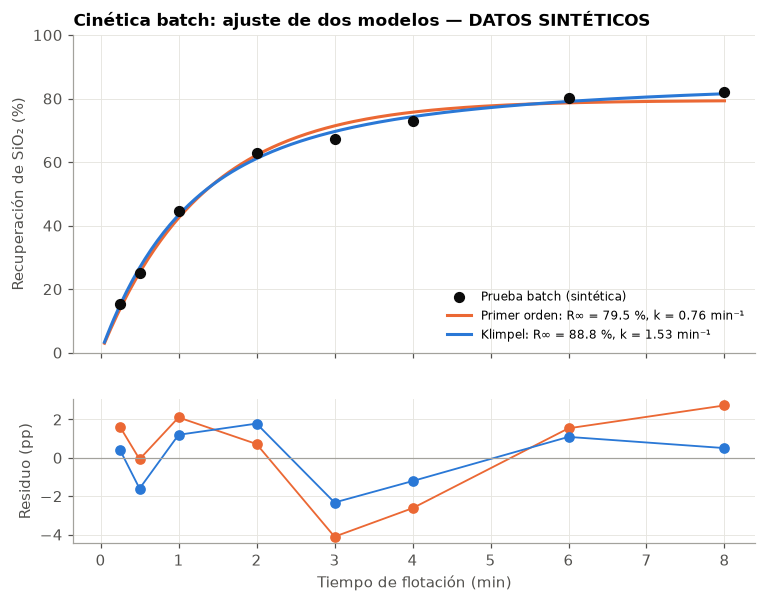

In [4]:
t_grid = np.linspace(0.05, TIMES.max(), 200)
colors = {"Primer orden": ORANGE, "Klimpel": BLUE}

fig, (ax, ax_res) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax.scatter(TIMES, recovery, s=40, color=TEXT, zorder=3, label="Prueba batch (sintética)")
for name, model in MODELS.items():
    f = fits[name]
    ax.plot(t_grid, model(t_grid, *f["params"]), color=colors[name], lw=2,
            label=f"{name}: R∞ = {f['params'][0]:.1f} %, k = {f['params'][1]:.2f} min⁻¹")
    ax_res.plot(TIMES, f["residuals"], color=colors[name], marker="o", lw=1.2)
ax.set_ylabel("Recuperación de SiO₂ (%)")
ax.set_ylim(0, 100)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Cinética batch: ajuste de dos modelos — DATOS SINTÉTICOS")
ax_res.axhline(0, color=GRAY, lw=0.8)
ax_res.set_ylabel("Residuo (pp)")
ax_res.set_xlabel("Tiempo de flotación (min)")
save(fig, "06_cinetica_ajuste")
plt.show()

## 4. Comparación de modelos

Los dos modelos tienen 2 parámetros y **no están anidados**, así que no aplica un test F. Se usa **AICc**
(AIC corregido para muestras chicas) y los pesos de Akaike, más la inspección de residuos: un patrón
sistemático (no aleatorio) indica un modelo mal especificado aunque el R² sea alto.

In [5]:
compare = pd.DataFrame({name: {"SSE": f["sse"], "RMSE": f["rmse"], "AICc": f["aicc"],
                               "corr(R∞, k)": f["corr_params"]} for name, f in fits.items()}).T
compare["ΔAICc"] = compare["AICc"] - compare["AICc"].min()
compare["peso_Akaike"] = np.exp(-compare["ΔAICc"] / 2) / np.exp(-compare["ΔAICc"] / 2).sum()
signs = {name: "".join("+" if r > 0 else "−" for r in f["residuals"]) for name, f in fits.items()}
compare["signos_residuos"] = pd.Series(signs)
compare.round(3)

,SSE,RMSE,AICc,"corr(R∞, k)",ΔAICc,peso_Akaike,signos_residuos
Primer orden,41.212,2.621,19.514,-0.697,7.715,0.021,+−++−−++
Klimpel,15.711,1.618,11.799,-0.808,0.000,0.979,+−++−−++


## 5. ¿Son confiables los IC? Monte Carlo

Repetimos la prueba sintética 1000 veces (mismo modelo generador, ruido nuevo) y medimos
(a) con qué frecuencia el IC 95 % contiene el valor verdadero y (b) con qué frecuencia el AICc elige el
modelo correcto. Esto solo se puede hacer porque los datos son sintéticos: conocemos la verdad.

In [6]:
N_SIM = 1000
truth = np.array(list(TRUE.values()))
hits = {name: np.zeros(2) for name in MODELS}
klimpel_chosen = 0
estimates = {name: [] for name in MODELS}
for s in range(N_SIM):
    r_sim = synthetic_batch_test(TIMES, **TRUE, noise_sd=NOISE_SD, model=klimpel, seed=SEED + 1 + s)
    sim_fits = {name: fit_kinetic(model, TIMES, r_sim) for name, model in MODELS.items()}
    for name, f in sim_fits.items():
        hits[name] += (f["ci_low"] <= truth) & (truth <= f["ci_high"])
        estimates[name].append(f["params"])
    klimpel_chosen += sim_fits["Klimpel"]["aicc"] < sim_fits["Primer orden"]["aicc"]

mc = pd.DataFrame({
    name: {"cobertura_IC_R∞": hits[name][0] / N_SIM,
           "cobertura_IC_k": hits[name][1] / N_SIM if name == "Klimpel" else np.nan,
           "media_R∞_estimado": np.mean(estimates[name], axis=0)[0],
           "media_k_estimado": np.mean(estimates[name], axis=0)[1]}
    for name in MODELS}).T
print(f"AICc elige Klimpel (el modelo verdadero) en {klimpel_chosen / N_SIM:.1%} de las pruebas")
mc.round(3)

AICc elige Klimpel (el modelo verdadero) en 90.9% de las pruebas


,cobertura_IC_R∞,cobertura_IC_k,media_R∞_estimado,media_k_estimado
Primer orden,0.000,NaN,80.494,0.751
Klimpel,0.942,0.945,89.966,1.505


**Nota sobre k:** la k de primer orden y la k de Klimpel **no son comparables**. En Klimpel, k es la
constante máxima de una distribución uniforme entre 0 y k (su media es k/2). Para comparar velocidades
entre modelos conviene usar una magnitud común, por ejemplo el tiempo para alcanzar el 50 % de R∞.

In [7]:
def t50(model, r_inf, k):
    grid = np.linspace(1e-3, 30, 30000)
    return grid[np.argmax(model(grid, r_inf, k) >= 0.5 * r_inf)]

pd.Series({name: t50(model, *fits[name]["params"]) for name, model in MODELS.items()},
          name="t50_min").round(2).to_frame()

,t50_min
Primer orden,0.91
Klimpel,1.04
